What is image padding?

-Suppose our original grayscale image is:

100 120 150

80  90  130

60  70  110

-If the user says:

Border width = 1 pixel

Border color = 255

-We add one row/column of pixels around the image:

255 255 255 255 255

255 100 120 150 255

255 80  90  130 255

255 60  70  110 255

255 255 255 255 255

-So the image becomes larger.

If original dimensions are:

New height = H + 2b

New width  = W + 2b



Why do we need padding?

Padding is commonly used in image processing because operations such as:

filtering ,
convolution,
edge detection,
morphological operations,

often need pixels around the boundary of an image.

Image Complement

For a binary image:

0 → 255

255 → 0

Grayscale complement

For an 8-bit grayscale image:

0 → 255

1 → 254

2 → 253

...

128 → 127

...

254 → 1

255 → 0

g(x,y)=255−f(x,y)



In [ ]:
# FIRST USING SIMPLE PYTHON CODE

# Q(1)

In [ ]:
!pip install pillow

from PIL import Image

# --------------------------------
# Function to add border
# --------------------------------

def add_border(image, border_width, border_color):

    width, height = image.size

    # New image dimensions
    new_width = width + 2 * border_width
    new_height = height + 2 * border_width

    # Create new image filled with border color
    padded_image = Image.new(
        image.mode,
        (new_width, new_height),
        border_color
    )

    # Copy original image into the center
    for y in range(height):
        for x in range(width):

            pixel = image.getpixel((x, y))

            padded_image.putpixel(
                (x + border_width, y + border_width),
                pixel
            )

    return padded_image


# --------------------------------
# Main program
# --------------------------------

# Using a default image path for demonstration purposes as 'abc' was not found.
# You can change this back to input("Enter image path: ") to prompt for a file.
image_path = "/content/abc.jpg" # Changed from input("Enter image path: ")

image = Image.open(image_path)

# Convert to grayscale
image = image.convert("L")

# Using default values for border_width and border_color for demonstration.
# You can change these back to int(input(...)) to prompt for values.
border_width = 1 # Changed from int(input("Enter border width: "))
border_color = 255 # Changed from int(input("Enter border color (0-255): "))

result = add_border(
    image,
    border_width,
    border_color
)

result.save("border_output.png")

result.show()

print("Border added successfully.")
print("Output saved as border_output.png")

Border added successfully.
Output saved as border_output.png


In [ ]:
# Q(2)

from PIL import Image

# --------------------------------
# Function for image complement
# --------------------------------

def image_complement(image):

    width, height = image.size

    result = Image.new("L", (width, height))

    for y in range(height):
        for x in range(width):

            pixel = image.getpixel((x, y))

            new_pixel = 255 - pixel

            result.putpixel(
                (x, y),
                new_pixel
            )

    return result


# --------------------------------
# Main program
# --------------------------------

image_path = input("Enter image path: ")

image = Image.open(image_path)

# Convert image to grayscale
image = image.convert("L")

result = image_complement(image)

result.save("complement_output.png")

result.show()

print("Image complement generated successfully.")
print("Output saved as complement_output.png")

Enter image path: /content/abc.jpg
Image complement generated successfully.
Output saved as complement_output.png


In [ ]:
# NOW USING OPEN CV

Enter image path: /content/abc.jpg
Enter border width: 2
Enter border color (0-255): 125


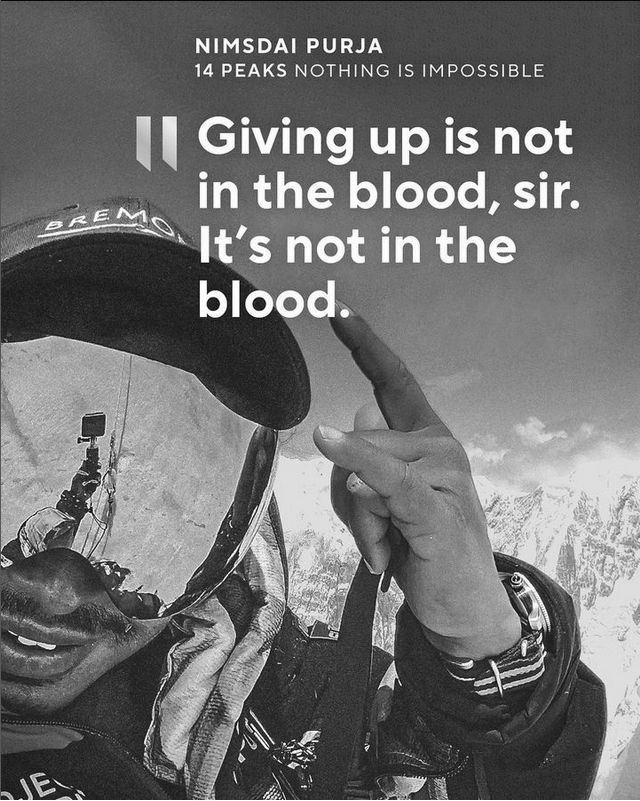

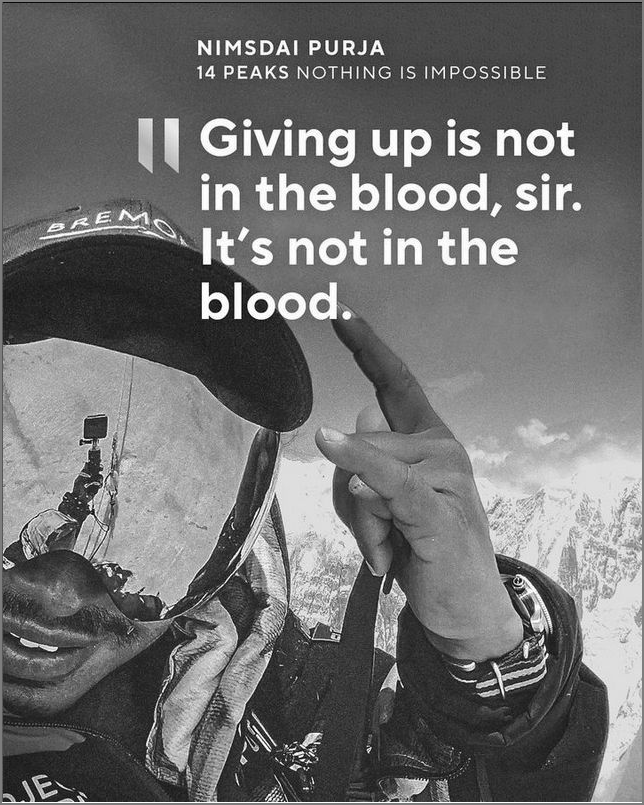

Border added successfully.


In [ ]:
import cv2
from google.colab.patches import cv2_imshow

# Read image
image_path = input("Enter image path: ")

image = cv2.imread(
    image_path,
    cv2.IMREAD_GRAYSCALE
)

# Check whether image was loaded
if image is None:
    print("Error: Image not found.")
    exit()

# Take input
border_width = int(input("Enter border width: "))
border_color = int(input("Enter border color (0-255): "))

# Add border
result = cv2.copyMakeBorder(
    image,
    border_width,
    border_width,
    border_width,
    border_width,
    cv2.BORDER_CONSTANT,
    value=border_color
)

# Display
cv2_imshow(image)
cv2_imshow(result)

# Save
cv2.imwrite("opencv_border_output.png", result)

# cv2.waitKey(0) # Not needed with cv2_imshow
# cv2.destroyAllWindows() # Not needed with cv2_imshow

print("Border added successfully.")

Enter image path: /content/abc.jpg


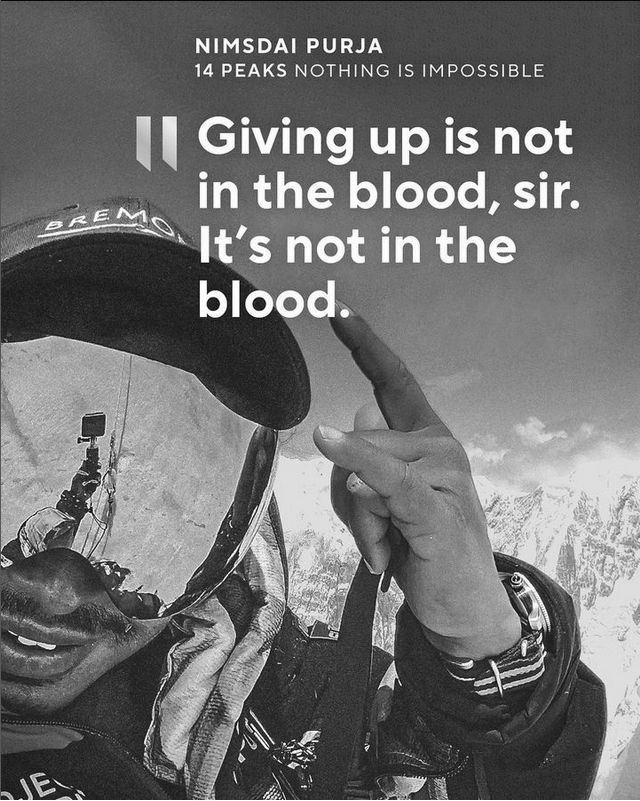

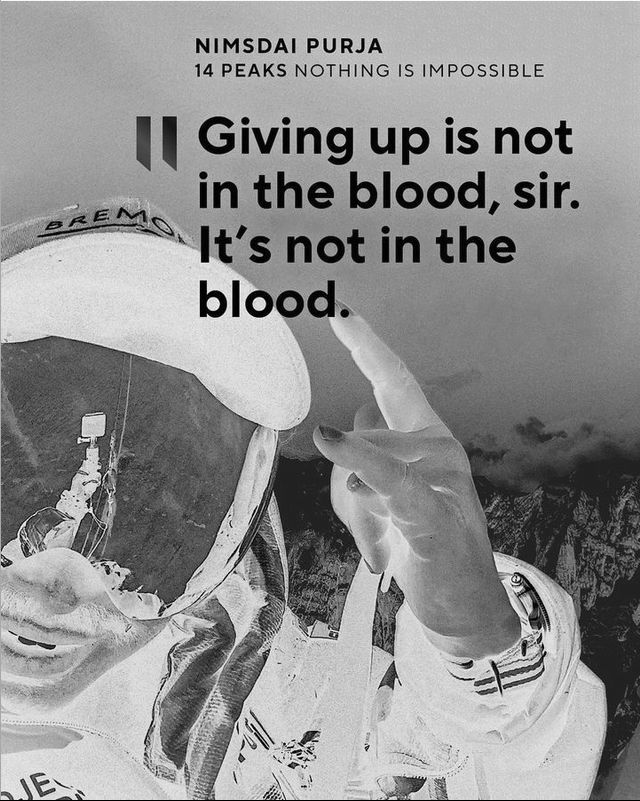

Image complement generated successfully.


In [ ]:
# Q(2)
import cv2
from google.colab.patches import cv2_imshow

# Read image
image_path = input("Enter image path: ")

image = cv2.imread(
    image_path,
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    print("Error: Image not found.")
    exit()

# Find complement
result = cv2.bitwise_not(image)

# Display
cv2_imshow(image)
cv2_imshow(result)

# Save
cv2.imwrite("opencv_complement_output.png", result)

# cv2.waitKey(0) # Not needed with cv2_imshow
# cv2.destroyAllWindows() # Not needed with cv2_imshow

print("Image complement generated successfully.")